# 03 - Geographic analysis (ENEM 2025)

**Questions answered here**
- Which states have the highest and lowest mean scores?
- Which region performs best overall and in each knowledge area?
- How different are states within the same region?
- Which states are the most balanced?

**Method notes**
- Source: INEP `RESULTADOS_2025.csv` (see notebook 02 for how the data was inspected and cleaned).
- Each area is averaged over participants marked present in that area. Blank objective answer sheets (score 0 with all answers blank) are excluded.
- Geography is the state where the exam was taken (`SG_UF_PROVA`), not the state of residence.
- Scales differ by area, so areas are never compared by raw points: comparisons are made within an area.

## 1. Setup

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from src import stats, plots
from src.config import AREAS, RAW_DIR, UF_REGION
from src.load import prepare_dataset

df, school = prepare_dataset()
print(df.shape)

(4810772, 19)


## 2. National means
Means over participants present in each area, excluding blank answer sheets.

In [2]:
national = stats.national_mean_std(df)
national_table = pd.DataFrame(national, index=["mean", "std"]).round(1)
print(national_table.to_string())

counts = {a: int((df[f"TP_PRESENCA_{a}"] == 1).sum()) for a in AREAS}
print(counts)

         CN     CH     LC     MT
mean  500.1  512.5  532.5  520.1
std    78.2   84.4   71.3  127.4
{'CN': 3259561, 'CH': 3448468, 'LC': 3455194, 'MT': 3259443}


## 3. Means by region

In [3]:
region_means = stats.mean_table(df, "REGION")
print(region_means.round(1).sort_values("LC", ascending=False).to_string())

                 CN     CH     LC     MT  ESSAY_WITH_ZEROS  ESSAY_VALID_ONLY     n_LC     n_CN
REGION                                                                                        
Sudeste       514.1  531.3  551.3  551.7             609.8             632.7  1167399  1102303
Sul           512.5  529.9  550.2  548.5             592.1             620.3   354425   327571
Centro-Oeste  504.8  516.5  535.9  524.1             593.2             624.4   271644   253100
Nordeste      490.0  497.1  518.7  497.3             563.0             613.5  1284526  1225204
Norte         476.3  487.5  502.4  471.1             532.3             585.0   377200   351383


## 4. Means by state

In [4]:
state_means = stats.mean_table(df, "SG_UF_PROVA")
print(state_means.round(1).sort_values("LC", ascending=False).to_string())

                CN     CH     LC     MT  ESSAY_WITH_ZEROS  ESSAY_VALID_ONLY    n_LC    n_CN
SG_UF_PROVA                                                                                
SP           517.6  535.3  556.9  560.5             607.3             627.1  544505  514386
DF           519.8  536.4  555.8  548.2             609.8             635.6   60607   56944
SC           517.3  534.5  553.1  553.7             601.2             631.9   79694   73247
RS           510.8  531.2  552.5  549.3             599.7             631.0  132335  121911
RJ           508.7  527.1  547.9  537.8             603.9             628.8  235413  222092
PR           511.3  526.1  546.4  544.8             580.0             603.9  142396  132413
MG           512.2  528.7  545.8  548.4             620.2             643.7  326626  309188
ES           512.9  526.9  543.1  545.3             598.6             639.2   60855   56637
RN           505.6  512.6  533.8  515.7             588.2             623.6   85

### Highest and lowest state in each column

In [5]:
columns = AREAS + ["ESSAY_WITH_ZEROS", "ESSAY_VALID_ONLY"]
rows = []
for column in columns:
    ordered = state_means[column].sort_values(ascending=False)
    rows.append({
        "column": column,
        "highest": f"{ordered.index[0]} {ordered.iloc[0]:.1f}",
        "second": f"{ordered.index[1]} {ordered.iloc[1]:.1f}",
        "lowest": f"{ordered.index[-1]} {ordered.iloc[-1]:.1f}",
    })
print(pd.DataFrame(rows).to_string(index=False))

          column  highest   second   lowest
              CN DF 519.8 SP 517.6 AM 471.7
              CH DF 536.4 SP 535.3 MA 482.9
              LC SP 556.9 DF 555.8 PA 496.0
              MT SP 560.5 SC 553.7 AM 464.7
ESSAY_WITH_ZEROS MG 620.2 GO 610.7 AM 500.5
ESSAY_VALID_ONLY MG 643.7 ES 639.2 AM 562.4


## 5. Absence rates by state
State means describe only the participants who showed up. If absence differs a lot between states, the means describe different shares of each state's registered population.

In [6]:
absence = stats.absence_rates(df, "SG_UF_PROVA")
summary = state_means[["LC", "CN"]].join(absence).round(1)
print(summary.sort_values("absent_LC_%", ascending=False).to_string())
print()
print(summary.corr().round(2))

                LC     CN  absent_LC_%  absent_CN_%
SG_UF_PROVA                                        
AM           503.7  471.7         40.7         45.8
RR           520.0  494.1         36.1         41.6
MT           526.1  496.0         35.7         40.8
AC           514.4  480.6         34.3         38.9
RO           512.7  486.1         32.3         37.0
AP           511.2  478.8         30.7         35.5
PA           496.0  473.9         29.8         34.4
MG           545.8  512.2         29.6         33.4
BA           517.1  488.7         29.2         33.0
TO           513.3  482.9         29.1         34.0
MS           530.5  500.1         29.1         34.1
ES           543.1  512.9         29.0         34.0
RS           552.5  510.8         28.9         34.6
GO           531.8  502.5         28.7         33.7
RJ           547.9  508.7         28.3         32.4
SC           553.1  517.3         27.7         33.6
MA           502.1  473.2         27.7         31.7
SP          

## 6. Spread inside each state (LC)
The standard deviation is the spread of individual scores. It is the yardstick for how large the differences between states are.

In [7]:
spread = stats.score_spread(df, "SG_UF_PROVA", "LC").round(1)
print(spread.sort_values("mean", ascending=False).to_string())
print()
top, bottom = spread["mean"].max(), spread["mean"].min()
print("Highest minus lowest state mean:", round(top - bottom, 1))
print("National std of individual scores:", round(national["LC"][1], 1))

              mean  median   std
SG_UF_PROVA                     
SP           556.9   562.7  64.6
DF           555.8   560.2  68.9
SC           553.1   557.2  61.2
RS           552.5   556.7  64.5
RJ           547.9   553.1  66.8
PR           546.4   551.2  64.6
MG           545.8   551.0  67.5
ES           543.1   548.7  66.6
RN           533.8   538.5  68.5
GO           531.8   537.4  69.7
MS           530.5   536.4  68.0
MT           526.1   533.1  69.1
PB           524.7   529.6  69.3
PE           524.4   529.7  69.6
CE           522.4   529.7  73.8
RR           520.0   527.7  70.6
SE           519.3   524.7  72.4
BA           517.1   523.6  70.7
AL           514.7   520.6  71.3
AC           514.4   520.9  68.8
TO           513.3   518.9  70.2
RO           512.7   520.4  67.3
AP           511.2   518.0  69.8
PI           511.0   515.2  74.0
AM           503.7   510.7  74.4
MA           502.1   507.8  71.1
PA           496.0   501.5  72.6

Highest minus lowest state mean: 60.9
Nati

## 7. Differences between states of the same region (LC)

In [8]:
print(stats.range_within_group(state_means, "LC", UF_REGION).round(1).to_string())

                min    max  range
group                            
Sul           546.4  553.1    6.7
Sudeste       543.1  556.9   13.8
Norte         496.0  520.0   24.0
Centro-Oeste  526.1  555.8   29.8
Nordeste      502.1  533.8   31.7


## 8. Profile across areas (z-scores)
Each state mean is expressed in standard deviations of individual scores above or below the national mean **of the same area**. This describes relative position within each area; it does not claim that areas measure the same thing.

In [9]:
z = stats.state_zscores(state_means, national)
print(z.round(2).sort_values("range").to_string())

               CN    CH    LC    MT  range
SG_UF_PROVA                               
MT          -0.05 -0.07 -0.09 -0.09   0.04
GO           0.03 -0.00 -0.01  0.01   0.04
ES           0.16  0.17  0.15  0.20   0.05
MS           0.00 -0.02 -0.03 -0.05   0.05
TO          -0.22 -0.23 -0.27 -0.26   0.05
PR           0.14  0.16  0.20  0.19   0.05
MG           0.16  0.19  0.19  0.22   0.07
CE          -0.10 -0.13 -0.14 -0.07   0.07
SC           0.22  0.26  0.29  0.26   0.07
PE          -0.06 -0.14 -0.11 -0.07   0.08
AL          -0.17 -0.23 -0.25 -0.22   0.08
MA          -0.34 -0.35 -0.43 -0.39   0.08
PI          -0.22 -0.28 -0.30 -0.22   0.08
PB          -0.03 -0.10 -0.11 -0.11   0.09
RN           0.07  0.00  0.02 -0.03   0.10
RO          -0.18 -0.23 -0.28 -0.25   0.10
SE          -0.10 -0.16 -0.18 -0.20   0.10
BA          -0.15 -0.21 -0.22 -0.26   0.11
DF           0.25  0.28  0.33  0.22   0.11
RJ           0.11  0.17  0.22  0.14   0.11
SP           0.22  0.27  0.34  0.32   0.12
AC         

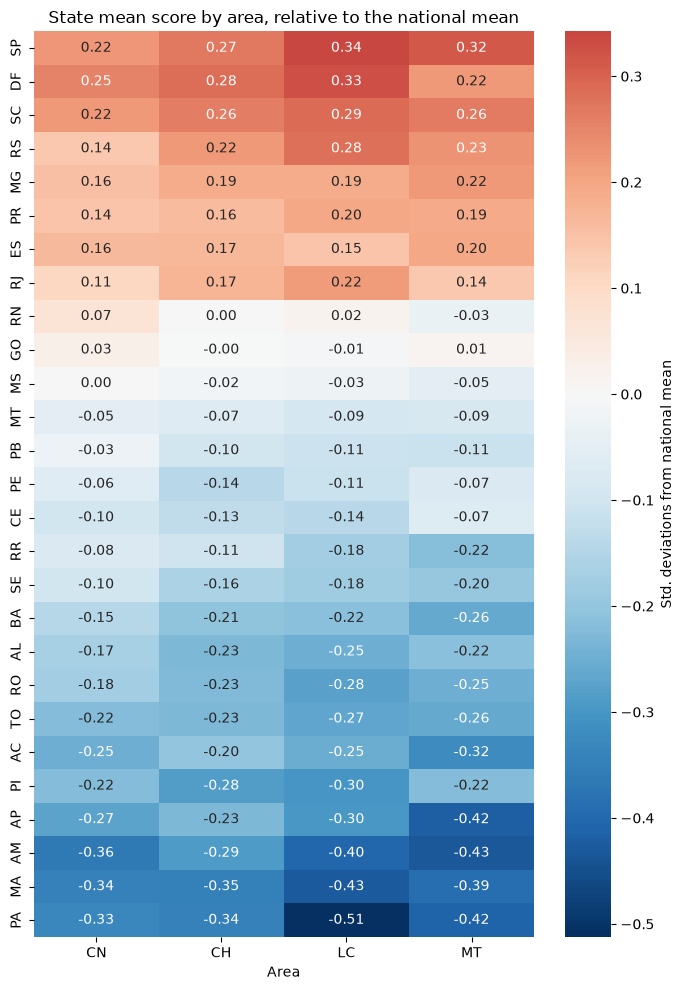

In [10]:
fig = plots.zscore_heatmap(z)
plots.save_figure(fig, "heatmap_state_area_z.png")
plt.show()

## 9. Mean LC score by state

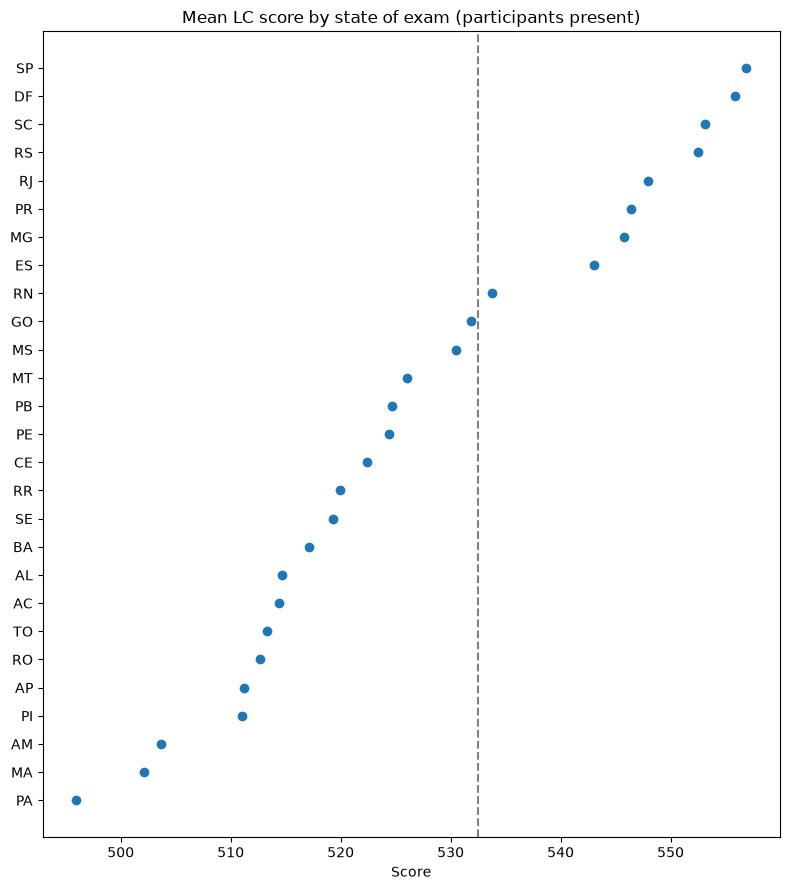

In [11]:
national_lc = national["LC"][0]
fig = plots.state_dot_plot(state_means, area="LC", national_mean=national_lc)
plots.save_figure(fig, "lc_by_state.png")
plt.show()

## 10. Map (requires the IBGE state shapefile)

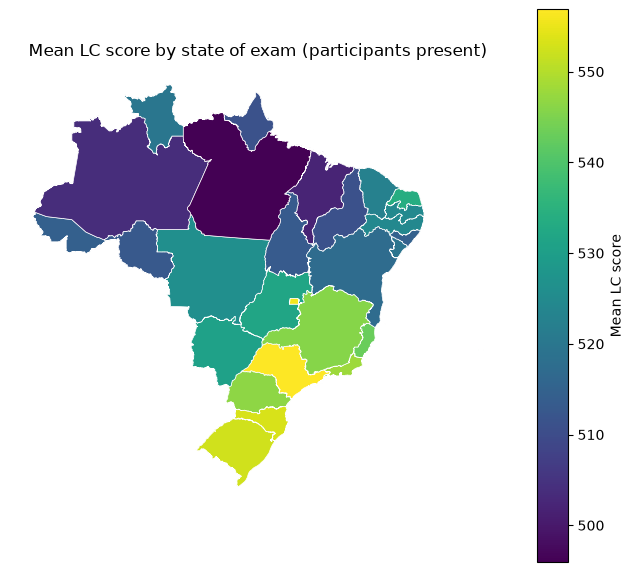

In [12]:
import geopandas as gpd

shapefiles = list(RAW_DIR.parent.glob("ibge_uf_2025/*.shp"))
if shapefiles:
    shapes = gpd.read_file(shapefiles[0])
    fig = plots.state_map(
        shapes, state_means, "LC",
        "Mean LC score by state of exam (participants present)",
    )
    plots.save_figure(fig, "map_lc_by_state.png")
    plt.show()
else:
    print("Shapefile not found in data/raw/ibge_uf_2025")

## 11. Findings

**Observed**
- The Southeast has the highest mean in all four objective tests and the North has the lowest. The South is within about 1 to 3 points of the Southeast in the objective tests. In the essay, the Center-West is slightly above the South when zeros are included.
- Which state is "highest" depends on the column: the answer changes between CN/CH, LC/MT and the two essay averages (see section 4).
- Within-region differences in LC are smallest in the South and largest in the Northeast and Center-West (section 7). The Federal District stands well above its Center-West neighbors.
- A state is usually above (or below) the national mean in all four areas. Differences between areas inside one state are small, at most about 0.2 standard deviations (section 8).
- The gap between the highest and lowest state mean in LC is about the size of the standard deviation of individual scores. There is far more variation among people inside a state than between states.
- Absence rates differ a lot between states (section 5).

**Hypotheses (not tested here)**
- Differences in who registers and who shows up may explain part of the state differences.
- Some of the essay differences between states may come from different shares of invalid (zero) essays.

**What these results do not show**
- They do not show that education quality differs between states: the data compare exam takers, not residents, and there is no socioeconomic control.
- Differences of 1 to 2 points between neighboring states are not meaningful given the spread of individual scores.
- Raw scores of different areas must not be compared with each other.